In [2]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.quantum_info import Statevector, SparsePauliOp
import numpy as np
import matplotlib.pyplot as plt


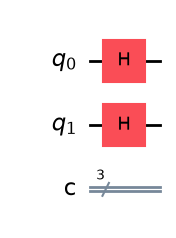

In [3]:
qc = QuantumCircuit(2,3)
qc.h(0)
qc.h(1)
qc.draw(output='mpl', filename='circuit.png')

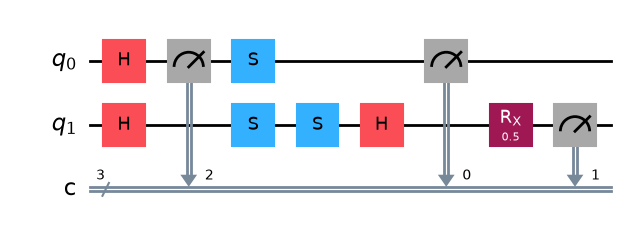

In [4]:
def build(D_1,D_2):
    qc = QuantumCircuit(2,3)
    qc.h(0)
    qc.h(1)
    
    for i,op in [(0,D_1),(1,D_2)]:
        if op == 'I':
            qc.id(i)
        elif op == 'Z':
            qc.z(i)
        elif op == 'S':
            qc.s(i)
        elif op == 'Sdg':
            qc.sdg(i)
        elif op == 'M':
            qc.measure(i,2)
        else:
            raise ValueError(f"Invalid operator: {op}")

    qc.s(0)
    qc.s(1)
    qc.h(1)
    qc.rx(0.5,1)
    qc.measure(0,0)
    qc.measure(1,1)
    return qc

a= build("M", "S")
a.draw(output='mpl', filename='circuit.png')

I ⊗ I   weight +0.5


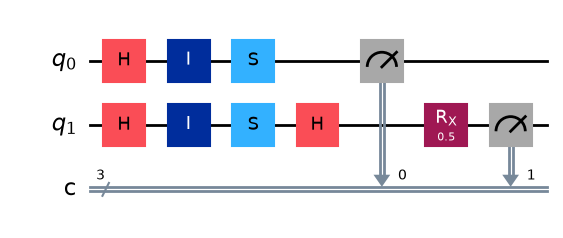

Z ⊗ Z   weight +0.5


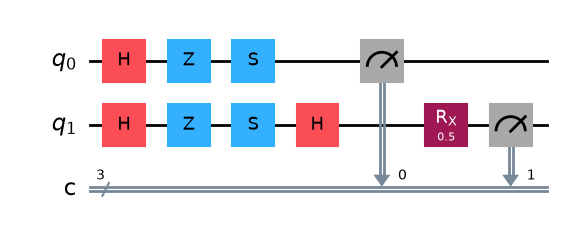

M ⊗ S   weight -0.5


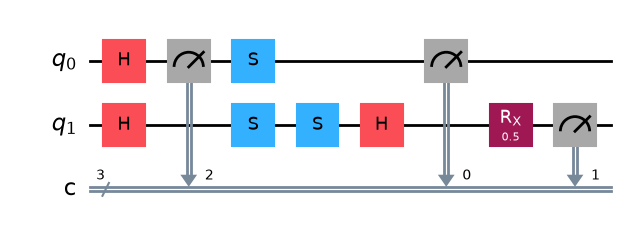

M ⊗ Sdg   weight +0.5


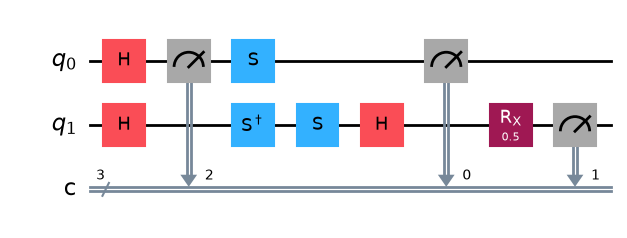

S ⊗ M   weight -0.5


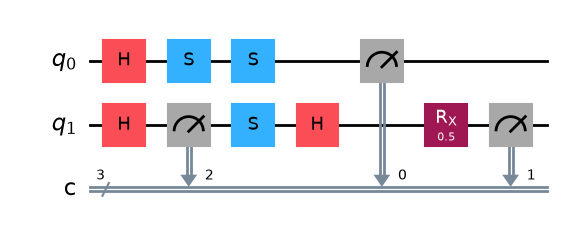

Sdg ⊗ M   weight +0.5


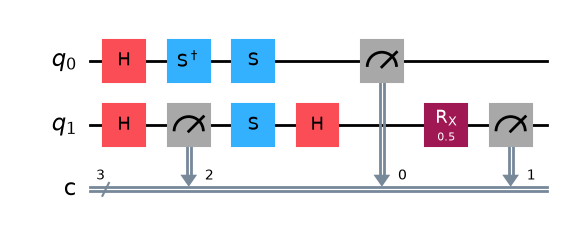

In [5]:
terms = [
    ("I",   "I",   +0.5),
    ("Z",   "Z",   +0.5),
    ("M",   "S",   -0.5),
    ("M",   "Sdg", +0.5),
    ("S",   "M",   -0.5),
    ("Sdg", "M",   +0.5),
]

circuits = [build(d1, d2) for d1, d2, w in terms]

for (d1, d2, w), qc in zip(terms, circuits):
    print(f"{d1} ⊗ {d2}   weight {w:+}")
    display(qc.draw(output='mpl'))

In [6]:
sim = AerSimulator()
Simulation = sim.run(circuits, shots=1024).result()
print(Simulation.get_counts(circuits[0]))

{'000': 124, '011': 387, '010': 377, '001': 136}


In [7]:
sim = AerSimulator()
shots = 4096

all_counts = []
for (d1, d2, w), qc in zip(terms, circuits):
    counts = sim.run(transpile(qc, sim), shots=shots).result().get_counts()
    all_counts.append(counts)
    print(f"{d1} ⊗ {d2}:", counts)

I ⊗ I: {'011': 1502, '000': 551, '010': 1504, '001': 539}
Z ⊗ Z: {'001': 1526, '000': 1465, '011': 549, '010': 556}
M ⊗ S: {'010': 1973, '111': 1872, '101': 138, '000': 113}
M ⊗ Sdg: {'000': 1961, '101': 1880, '010': 121, '111': 134}
S ⊗ M: {'111': 495, '100': 496, '011': 521, '101': 496, '000': 517, '110': 527, '010': 538, '001': 506}
Sdg ⊗ M: {'111': 494, '110': 539, '100': 516, '001': 502, '011': 512, '010': 524, '101': 500, '000': 509}


In [8]:
def value(counts,shots):
    total = 0
    for bits,n in counts.items():
        mid = int(bits[0])
        q1 = int(bits[1])
        q2 = int(bits[2])
        zz = (-1)**(q1+q2)
        sign = (-1)**mid

        total += zz*sign*n
    return total/shots

for (d1, d2, w), counts in zip(terms, all_counts):
    print(f"{d1} ⊗ {d2}:  value = {value(counts, shots):+.3f}")


I ⊗ I:  value = +0.002
Z ⊗ Z:  value = -0.017
M ⊗ S:  value = -0.877
M ⊗ Sdg:  value = +0.875
S ⊗ M:  value = +0.006
Sdg ⊗ M:  value = +0.006


In [9]:
cut_value = 0
for (d1, d2, w), counts in zip(terms, all_counts):
    cut_value += w * value(counts, shots)

# Exact answer from the original circuit with a real CNOT
ref = QuantumCircuit(2)
ref.h(0)
ref.cx(0, 1)
ref.rx(0.5, 1)
exact_value = Statevector(ref).expectation_value(SparsePauliOp("ZZ")).real

print("Hand-built cut:", cut_value)
print("Exact:         ", exact_value)
print("Error:         ", abs(cut_value - exact_value))

Hand-built cut: 0.869140625
Exact:          0.8775825618903725
Error:          0.008441936890372537


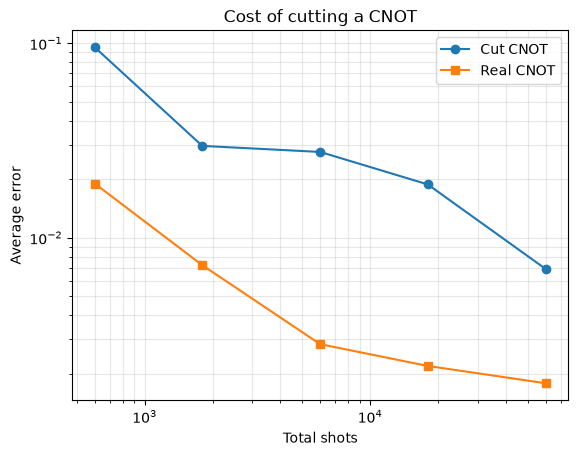

   600 shots   cut err 0.0955   real err 0.0190   ratio 5.0x
  1800 shots   cut err 0.0297   real err 0.0072   ratio 4.1x
  6000 shots   cut err 0.0276   real err 0.0028   ratio 9.7x
 18000 shots   cut err 0.0188   real err 0.0022   ratio 8.6x
 60000 shots   cut err 0.0069   real err 0.0018   ratio 3.9x


In [10]:
def run_cut(total_shots):
    s = total_shots // 6              # split the budget across the 6 circuits
    est = 0
    for d1, d2, w in terms:
        counts = sim.run(transpile(build(d1, d2), sim), shots=s).result().get_counts()
        est += w * value(counts, s)
    return est

def run_uncut(total_shots):
    r = ref.copy()
    r.measure_all()
    counts = sim.run(transpile(r, sim), shots=total_shots).result().get_counts()
    return sum((-1) ** (int(k[0]) + int(k[1])) * n for k, n in counts.items()) / total_shots

shot_list = [600, 1800, 6000, 18000, 60000]
trials = 10

cut_err   = [np.mean([abs(run_cut(N)   - exact_value) for _ in range(trials)]) for N in shot_list]
uncut_err = [np.mean([abs(run_uncut(N) - exact_value) for _ in range(trials)]) for N in shot_list]

plt.loglog(shot_list, cut_err, 'o-', label='Cut CNOT')
plt.loglog(shot_list, uncut_err, 's-', label='Real CNOT')
plt.xlabel('Total shots')
plt.ylabel('Average error')
plt.title('Cost of cutting a CNOT')
plt.legend()
plt.grid(True, which='both', alpha=0.3)
plt.show()

for N, c, u in zip(shot_list, cut_err, uncut_err):
    print(f"{N:>6} shots   cut err {c:.4f}   real err {u:.4f}   ratio {c/u:.1f}x")